# PRUEBA DE ANÁLISIS DE PARADAS

## ANÁLISIS INICIAL
De primeras el análisis se hará sobre una parada concreta, la 5939 correspondiente a la linea 401 siendo la quinta parada de la línea. He escogido esta debido a que la considero muy básica para empezar, puesto que esa parada no tiene correspondencia con ninguna otra línea, por lo tanto los datos de ocupación o de subidas/bajadas no se verían afectados en tanto qué otros autobuses puedan pasar por esa parada, lo cual como caso base es mejor.

In [325]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


np.random.seed(495794)


#ABRIR EL CSV COMO PANDAS DATAFRAME
data_input = pd.read_csv("../data/clean_data_5939.csv", encoding="utf-8", header=0)
dataset = pd.DataFrame(data_input)

Borramos las columnas que se duplican, como EventTime, TimeSlot e IdExternal, ya que aparecen en ambas tablas mbot y tbso

In [326]:
dataset.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

Se eliminan aquellas filas cuya ocupación sea < 0, puesto que como se dijo en el documento adjunto con la información de la base de datos, estas instancias no tienen sentido

In [327]:
dataset.shape

(9380, 25)

In [328]:
dataset = dataset[dataset["Occupation"] >=0]
dataset = dataset[dataset["Occupation"] < 500] #Fijamos 500 como valor arbitrariamente grande, puesto que se ha dado el caso que a veces hay valores extremadamente grandes

In [329]:
dataset.shape

(9320, 25)

Se han visto afectadas +- unas 60 filas, teniendo en cuenta que días únicos a día de ejecutar la consulta tenemos unos 120 días, es una media estimada de 1 medida erronea cada 2 días de medición

## ESTUDIO DE LA OCUPACIÓN
### ANÁLISIS DE UN DÍA

Para comenzar desde lo más básico, vamos a analizar las distribuciones de 1 día cconcreto, porejemplo el lúnes 22/9, y posteriormente, se irán añadiendo más días, para analizar parecidos, o casos partiulares.

In [330]:
data_22_9 = dataset[dataset["EventDate"] == "2025-09-22"]
data_22_9.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

A continuación se muestra una distribución del valor de **Occupation** en función del tiempo de registro en la parada. Esto no hace falta reordenarlo,ya que en la propia consulta, se hacía un order by EventTime, lo que nos ayuda a mostrar todos estos estadísticos en función de la hora del día.

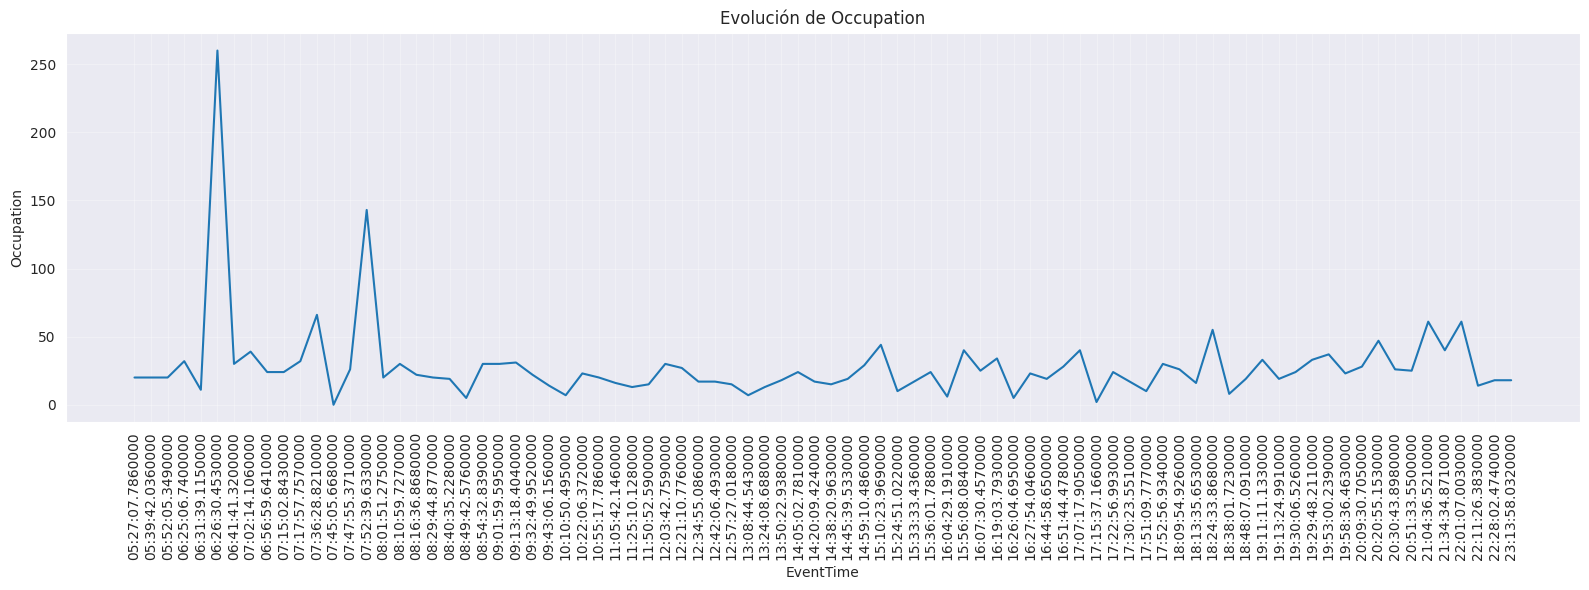

In [331]:
plt.figure(figsize=(16,6))
plt.plot(data_22_9["EventTime"], data_22_9["Occupation"])
plt.xlabel('EventTime')
plt.ylabel('Occupation')
plt.title('Evolución de Occupation')
plt.xticks(rotation= 90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

En la distribución de ocupación a lo largo del tiempo si que se puede observar una cosa curiosa. Se detectan 2 valores de ocupación muy altos, ubicados en las primeras horas de la mañana. Desconozco según el tamaño del autobús si es verídico o no el caso de que haya más de 250 o de 140 personas en un autobús, siendo en mi opinión poco creible, por lo que vamos a eliminar ambos valores.

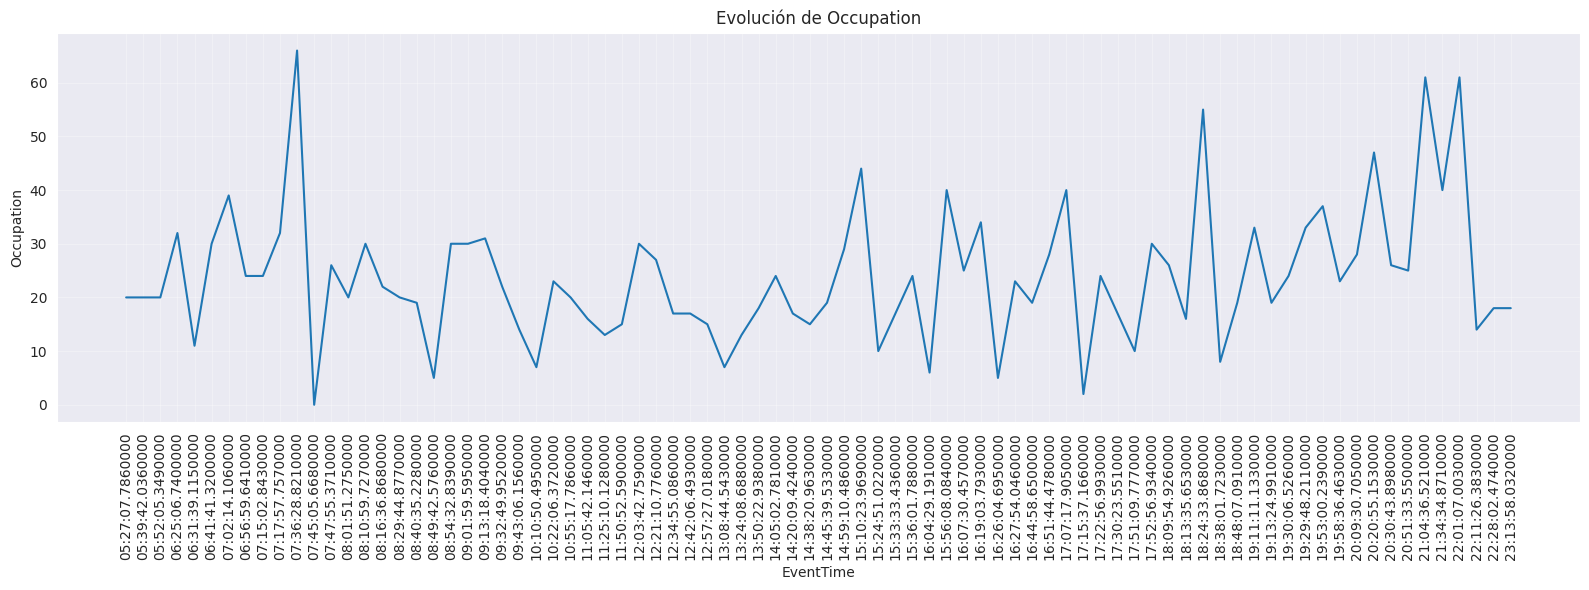

In [332]:
data_22_9 = data_22_9[data_22_9["Occupation"] <140]

dataset = dataset[dataset["Occupation"] < 140] #Considero la misma condición para todo el dataset, no solo para este día en concreto

#DEFINIMOS UNA FUNCION QUE DIBUJE ESTA GRAFICA

def project_occupation_in_daytime(data_to_project):
    plt.figure(figsize=(16,6))
    plt.plot(data_to_project["EventTime"], data_to_project["Occupation"])
    plt.xlabel('EventTime')
    plt.ylabel('Occupation')
    plt.title('Evolución de Occupation')
    plt.xticks(rotation=90)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
project_occupation_in_daytime(data_22_9)

Aquí ya se puede ver un poco mejor la situación. Se puede observar como la tendencia a lo largo de este día en concreto es muy ruidosa, dando lugar a variaciones de ocupación entre horas muy cercanas(Ej: ocupación de 55 a las 18:24 y de 9 a las 18:38, o de ~65 a las 7:36 y de 0 a las 7:45). No se observa de momento o a priori una tendencia clara.

Vamos a ver la distribución de probabilidad que sigue la variable aleatoria occupation para este día en concreto, a ver si esta tiene un comportamiento gaussiano o no.


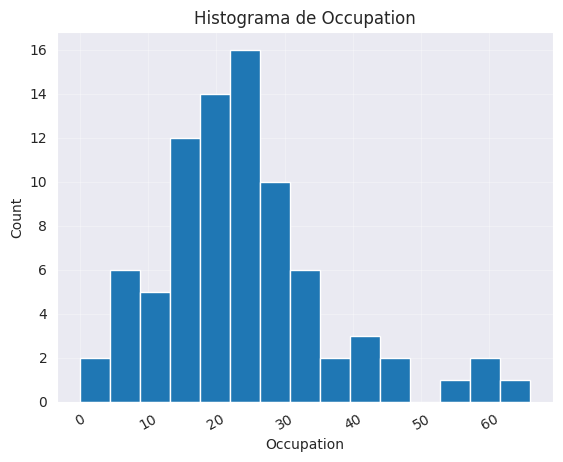

In [333]:
def histogram(data_hist, variable):
    plt.hist(data_hist[variable], bins= 15)
    plt.xlabel(variable)
    plt.ylabel('Count')
    plt.title(f"Histograma de {variable}")
    plt.xticks(rotation=29)
    plt.grid(True, alpha=0.3)
    plt.show()

histogram(data_22_9, "Occupation")

Aquí se ve como la variable occupation tiene una tendencia que a simple vista se puede asemejar a una campana de Gauss, aunque no tiene completa simetría. Para analizar mejor esta tendencia, vamos a someter a estos datos a unos experimentos que miden la simetría y la kurtosis de una variable aleatoria, con el fín de estimar su "normalidad". Los valores de skewness y kurtosis se miden calculando y estandarizando los momentos centrales de una distribución.

Estos momentos centrales se obtienen a partir de la formulación de los momentos algebráicos, denotados $ \mu_r' $ donde $r$ especifica el orden
$$
\mu_r' = E(x^r) = \sum_k k^r\, p(k)
\qquad \text{o} \qquad
\int_{-\infty}^{\infty} x^r f(x)\, dx
$$

Donde $E$ es la esperanza, $x$ y $k$ son representaciones de la variable aleatoria, tanto en su versión discreta($k$), como en su versión contínua($x$) y $r$ es el orden de magnitud del momento a calcular.


Estos momentos se calculan a partir del origen, mientras que los momentos centrales, **$\mu_r$** se calculan sobre el valor de la media, el cual se sabe como el momento algebráico **$\mu_1'$**. Estos valores **$\mu_r$** se obtienen a partir de:
$$
\mu_r = E\left[(k - E(k)\,)^{r}\right]
$$
De esta fórmula general obtenemos los momentos centrales **$\mu_1$** (Media), **$\mu_2$** (Varianza), **$\mu_3$** (skewness)[sin estandarizar] y **$\mu_4$** (kurtosis)[sin estandarizar]. Se puede obtener para una muestra de $n$ observaciones, podemos definir el cálculo de los momentos algebráicos $m_r'$ y de los momentos centrales $m_r$ como:

$$
m_r' = \frac{1} {n} \sum_{x=0}^{n}x^r
\qquad \text{y} \qquad
m_r = \frac{1} {n} \sum_{x=0}^{n}(x - m_1')^r
$$

Donde, para estandarizar una fórmula general de skewness y kurtosis, se consideran unas fórmulas genéricas a usar en vez de los momentos centrales 3 y 4, que derivan de estos, pero con la siguiente diferencia.

Se considera skewness $\gamma_1$ y kurtosis $\gamma_2$ como:
$$
\gamma_1 = \frac{\mu_3} {\mu_2^{3/2}}
\qquad \text{y} \qquad
\gamma_2 = \frac{\mu_4} {\mu_2^{2}} - 3
$$

Donde se denota que los exponentes de los denominadores de ambas fórmulas se usan para eliminar las unidades de los valores $\gamma$, puesto que los momentos centrales $\mu_r$ presentan grado r, y como se comparan estos con la varianza $\mu_2$ hay que elevar este exponente a lo necesario para que ambos numerador y denominador estén sujetos a las mismas unidades, y el resultado sea adimensional. También se destaca que de la fórmula de la kurtosis se le resta 3 al valor. Esto es debido a que es un estandar considerar kurtosis como el "sobrante" de kurtosis que tiene la distribución normal. Como la distribución gaussiana presenta kurtosis 3, se resta este valor para considerar este exceso.

Y considerando el error de cada uno de los momentos centrales, como la aproximación mediante el teorema central del límite, se obtienen las fórmulas asintóticas para el SE(Error Estandar) de skewness y Kurtosis como:
$$
SE(\gamma_1) = \sqrt{\frac{6}{n}}
\qquad \text{y} \qquad
SE(\gamma_2) = \sqrt{\frac{24}{n}}
$$

Posteriormente se calcula el Z Score tanto para $\gamma_1$ como para $\gamma_2$ como lo siguiente:

$$
Z(\gamma_1) = \frac{\gamma_1} {SE(\gamma_1)}
\qquad \text{y} \qquad
Z(\gamma_12) = \frac{\gamma_2} {SE(\gamma_2)}
$$

Como posibles resultados, según los valores de skewness y kurtosis podemos encontrar lo siguiente:


Analizando según skewness ($\gamma_1$):
- Valor $0$ → indica simetría **perfecta**
- Valor $> 0$ → la cola derecha es mayor que la izquierda
- Valor $< 0$ → la cola izquierda es mayor que la derecha

Analizando según kurtosis ($\gamma_2$)*(Asumiendo kurtosis en exceso)* :
- Valor $0$ → distribución **mesocúrtica**, similar en pico a la normal
- Valor $> 0$ → distribución **leptocúrtica**, con un pico más alto que la normal
- Valor $< 0$ → distribución **platicúrtica**, más achatada que la normal



Para traspasar todo esto a código, se ha hecho uso de las siguientes funciones

In [334]:
import math

def central_moment(x, r):
    mean = np.mean(x)
    return sum((xi - mean) ** r for xi in x) / len(x)


def kurtosis(x):
    return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3

def skewness(x):
    return central_moment(x, 3) / central_moment(x, 2)**(3/2)



def is_normal(variables: list):
    if len(variables) < 50: #CASO Z score 1.96
        z_crit = 1.96
    elif len(variables) < 300: #CASO Z score 3.29
        z_crit = 3.29
    else:
        z_crit = "False"

    skew = skewness(variables)
    kurt = kurtosis(variables)


    n = len(variables)
    se_skew = math.sqrt(6.0 / n)
    se_kurt = math.sqrt(24.0 / n)

    z_skew = skew / se_skew
    z_kurt = kurt / se_kurt

    if z_crit != "False":
        approx_normal = (abs(z_skew) <= z_crit) and (abs(z_kurt) <= z_crit)
    else:
        approx_normal = (abs(skew) <= 2) and (abs(kurt) + 3 <= 7) #para muestras grandes de Z > 300 no se utilizan los errores, sino valores absolutos  de medida


    return {
        "n": n,
        "skewness": skew,
        "kurtosis_excess": kurt,
        "SE_skewness": se_skew,
        "SE_kurtosis": se_kurt,
        "Z_skewness": z_skew,
        "Z_kurtosis": z_kurt,
        "z_crit": z_crit,
        "is_approximately_normal": approx_normal,
    }



is_normal(data_22_9["Occupation"])

{'n': 82,
 'skewness': np.float64(1.0558861809999018),
 'kurtosis_excess': np.float64(1.712883855445547),
 'SE_skewness': 0.2705008904002297,
 'SE_kurtosis': 0.5410017808004594,
 'Z_skewness': np.float64(3.9034480789975445),
 'Z_kurtosis': np.float64(3.166133488343025),
 'z_crit': 3.29,
 'is_approximately_normal': np.False_}

Aquí podemos ver un dato crítico, la distribución, según el test de Z Score **NO** es gaussiana, rechazando la hipótesis por el valor de skewness, al ser este > 3.29(*teniendo en cuenta que $n$ es 84, por lo que ese es el Z Score referencia para $\alpha$ = 0.05*).
Se puede ver también que la kurtosis(por poco) pero si que encajaría con distribución gaussiana.
Las conclusiones según los valores de skewness o kurtosis que se pueden sacar son los siguientes:
- Skewness es > 0 (*Concretamente* 1.05) lo que indica que la distribución presenta mayor cola por el lado derecho, lo cual se podía ver bien en el histograma
- kurtosis es > 0 también (*Concretamente* 1.71) lo cual indica que la distribución es **leptocúrtica**, que indica que el pico es mayor que el de una distribución normal o gaussiana.

Para visualizar mejor este resultado, vamos a dibujar lo que sería una normal con media y desviación típica iguales a nuestra variable aleatoria, pero con valores que supondrían normalidad absoluta, $\gamma_1$,$\gamma_2$ = 0.

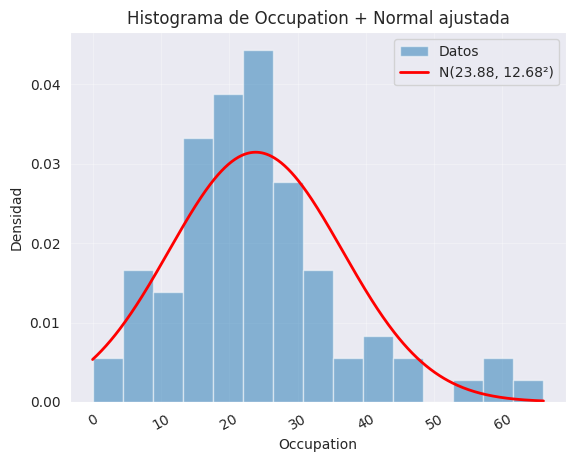

In [335]:
from scipy.stats import norm


def histogram_with_normal(data_to_hist, variable):
    data = np.asarray(data_to_hist[variable])
    mu = np.mean(data)
    sigma = np.std(data, ddof=0)

    # Histograma en densidad
    plt.hist(data,bins = 15, density=True, alpha=0.5, label="Datos")


    x = np.linspace(min(data), max(data), 400)
    y = norm.pdf(x, loc=mu, scale=sigma)
    plt.plot(x, y, 'r-', lw=2, label=f"N({mu:.2f}, {sigma:.2f}²)")

    plt.xlabel(variable)
    plt.ylabel('Densidad')
    plt.title(f"Histograma de {variable} + Normal ajustada")
    plt.xticks(rotation=29)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


histogram_with_normal(data_22_9, "Occupation")

Aquí se ven claramente los valores de $\gamma_1$ y $\gamma_2$ en la variable aleatoria estudiada y como difiere la distribución de una normal justo en los valores estimados de skewness y kurtosis.

Vamos a estudiar un par de Lunes más, a ver si este lunes es una anomalía estadística, o por el contrario, los lunes se comportan con una variable aleatoria de ocupacion que difiere de una distribución normal

In [336]:
data_29_9 = dataset[dataset["EventDate"] == "2025-09-29"]
data_29_9.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

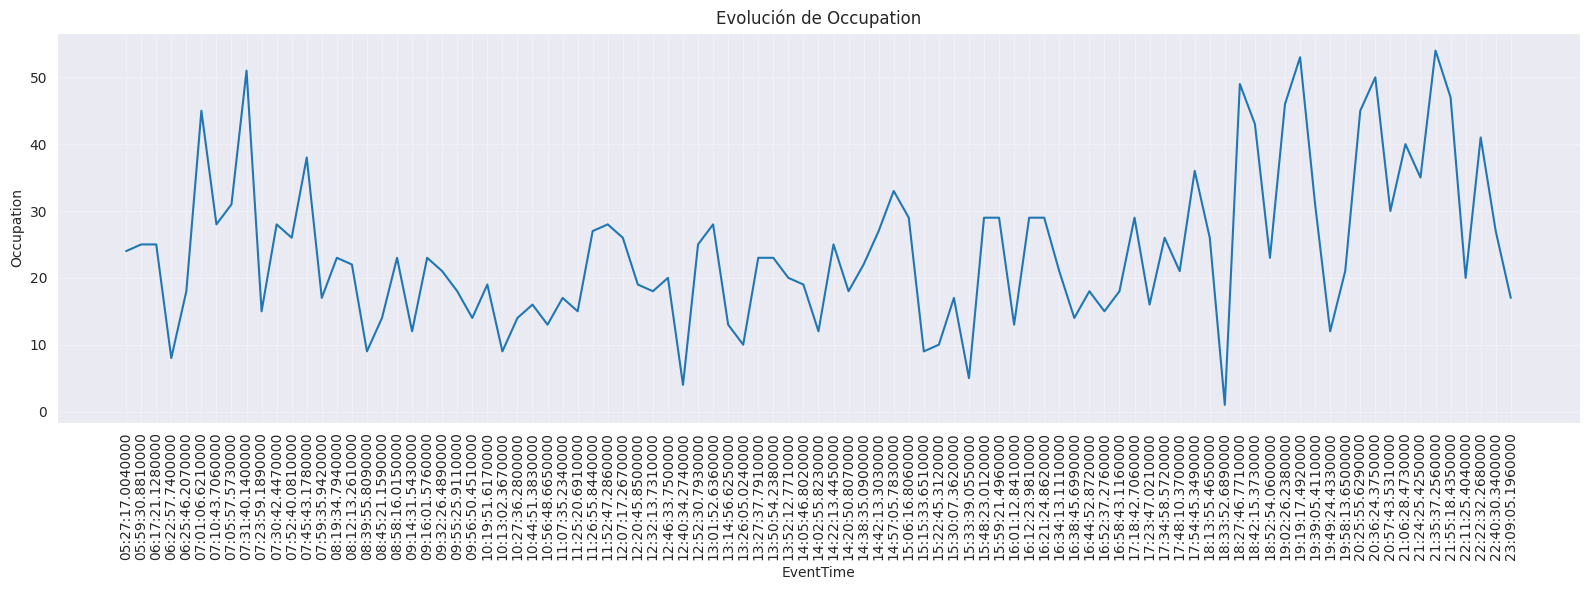

In [337]:
project_occupation_in_daytime(data_29_9)

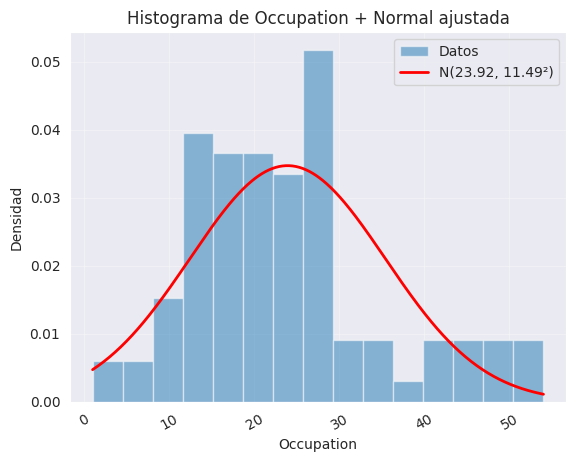

In [338]:
histogram_with_normal(data_29_9, "Occupation")

In [339]:
is_normal(data_29_9["Occupation"])

{'n': 93,
 'skewness': np.float64(0.7541385333987897),
 'kurtosis_excess': np.float64(0.24833729657207027),
 'SE_skewness': 0.254000254000381,
 'SE_kurtosis': 0.508000508000762,
 'Z_skewness': np.float64(2.9690463750388942),
 'Z_kurtosis': np.float64(0.4888524571548219),
 'z_crit': 3.29,
 'is_approximately_normal': np.True_}

En el caso del 29 de septiembre, pese a ver la distribución de probabilidad parecida a la del 22_9, el resultado del Z Score si que es positivo, por lo que se deduce que se acepta la hipótesis, y por lo tanto es factible decir que la variable aleatoria Occupation para ese día asume normalidad.
Vamos a probar un par de lunes más.

In [340]:
data_6_10 = dataset[dataset["EventDate"] == "2025-10-06"]
data_6_10.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

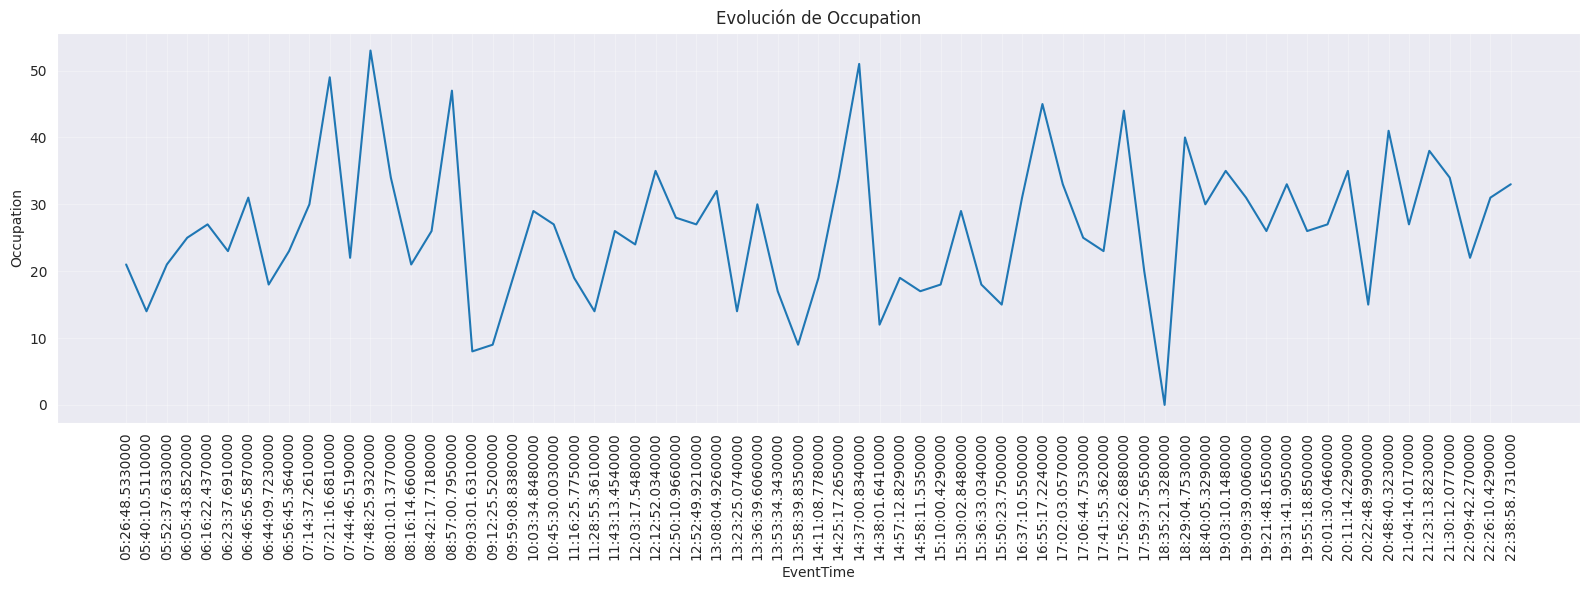

In [341]:
project_occupation_in_daytime(data_6_10)

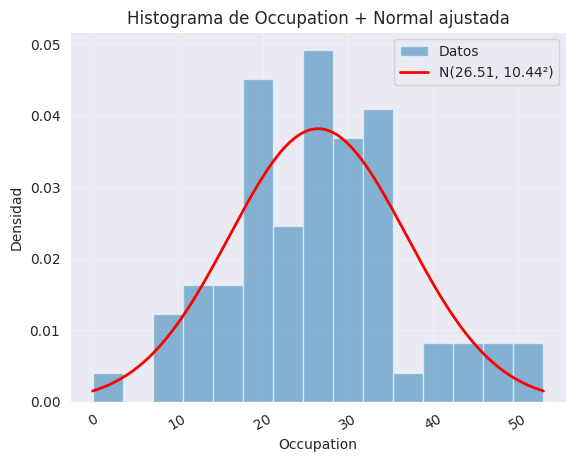

In [342]:
histogram_with_normal(data_6_10, "Occupation")

In [343]:
is_normal(data_6_10["Occupation"])

{'n': 69,
 'skewness': np.float64(0.28697193671984456),
 'kurtosis_excess': np.float64(0.20120617376266248),
 'SE_skewness': 0.29488391230979427,
 'SE_kurtosis': 0.5897678246195885,
 'Z_skewness': np.float64(0.9731691853652644),
 'Z_kurtosis': np.float64(0.3411616662751046),
 'z_crit': 3.29,
 'is_approximately_normal': np.True_}

Aquí se ve otro caso en el que se asume normalidad en la distribución de Occupation el lunes 6 de Octubre, dado que ambos valores de $\gamma_1$ y $\gamma_2$ tienen un Z score dentro de la zona de aceptación. Vamos a ver más días

In [344]:
data_13_10 = dataset[dataset["EventDate"] == "2025-10-13"]
data_13_10.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

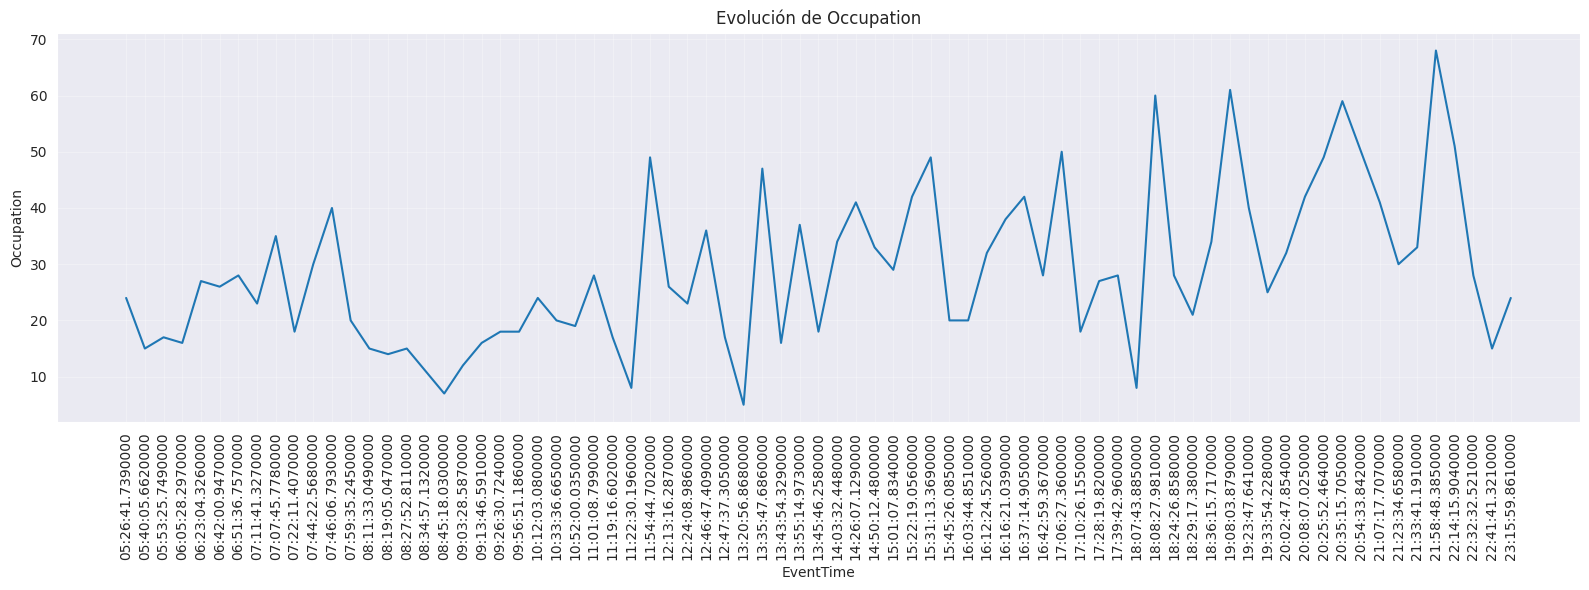

In [345]:
project_occupation_in_daytime(data_13_10)

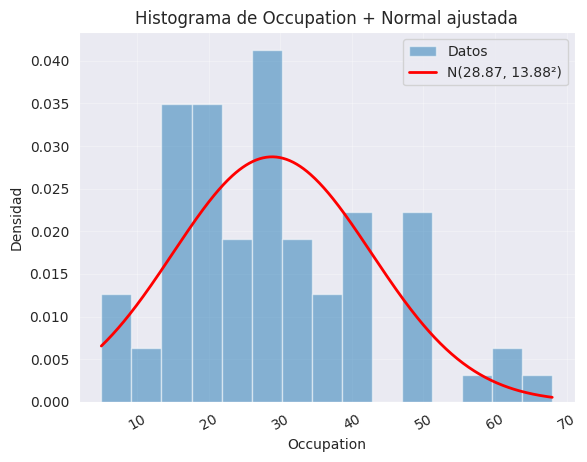

In [346]:
histogram_with_normal(data_13_10, "Occupation")

In [347]:
is_normal(data_13_10["Occupation"])

{'n': 75,
 'skewness': np.float64(0.6812694817323238),
 'kurtosis_excess': np.float64(-0.07018993955964792),
 'SE_skewness': 0.282842712474619,
 'SE_kurtosis': 0.565685424949238,
 'Z_skewness': np.float64(2.4086513517418546),
 'Z_kurtosis': np.float64(-0.12407945558425239),
 'z_crit': 3.29,
 'is_approximately_normal': np.True_}

Otro caso de Lunes el cuál si que asume una distribución normal. Vamos a revisar otro más

In [348]:
data_20_10 = dataset[dataset["EventDate"] == "2025-10-20"]
data_20_10.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

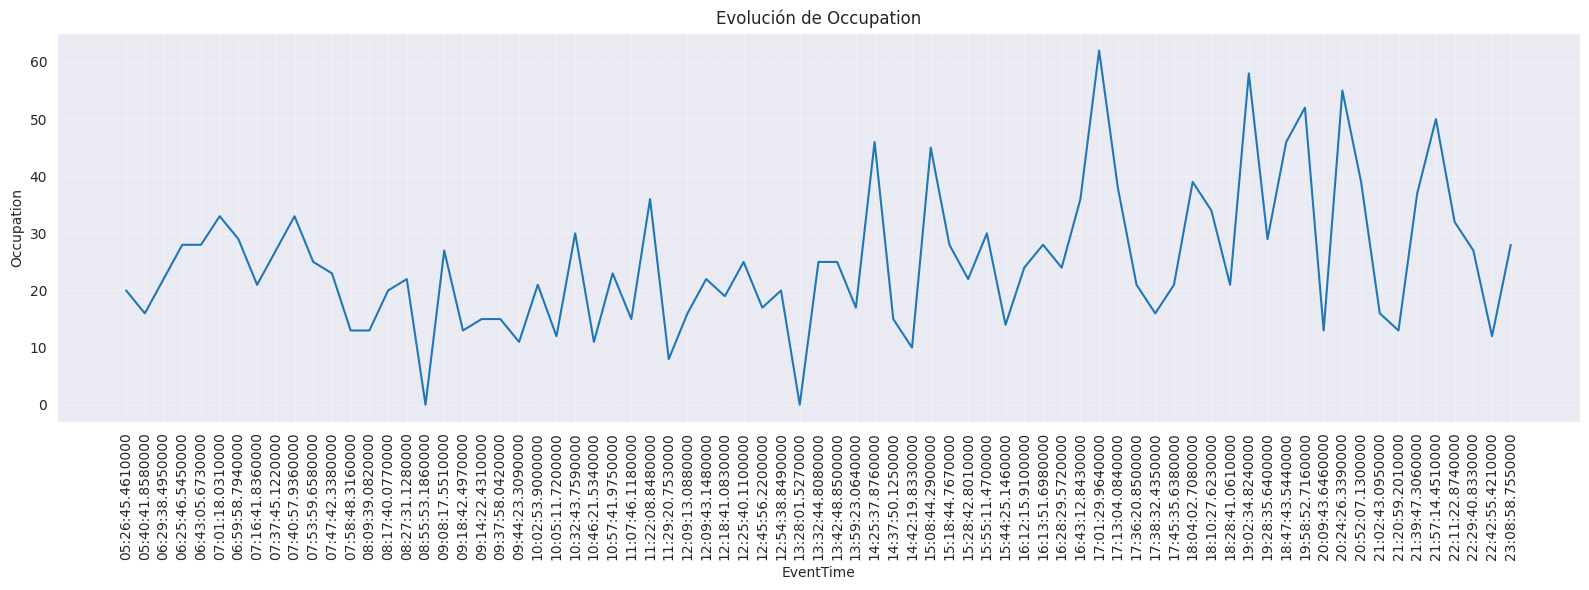

In [349]:
project_occupation_in_daytime(data_20_10)

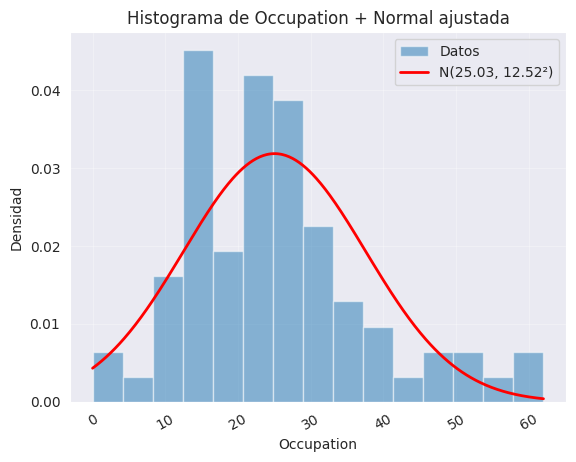

In [350]:
histogram_with_normal(data_20_10, "Occupation")

In [351]:
is_normal(data_20_10["Occupation"])

{'n': 75,
 'skewness': np.float64(0.8202518410194254),
 'kurtosis_excess': np.float64(0.6593012218757188),
 'SE_skewness': 0.282842712474619,
 'SE_kurtosis': 0.565685424949238,
 'Z_skewness': np.float64(2.900028195327928),
 'Z_kurtosis': np.float64(1.1654909120822434),
 'z_crit': 3.29,
 'is_approximately_normal': np.True_}

Una vez concluida esta pequeña prueba, de 5 lunes consecutivos tenemos los siguientes resultados:
- 4 de los Lunes tienen una distribución cuya hipótesis de normalidad queda validada según Z Test
- El primer Lunes analizado no asume normalidad debido a exceso de skewness Positivo

Habiendo cuenta de estos resultados, vamos a intentar encontrar una razon(si existe) de por qué este Lunes 22/9 no asume normalidad en la distribución de probabilidad de los datos de ocupación de los autobuses.

Para ello, vamos a ver el resto de variables que puedan haber afectado a la distribución de ese día. Sabiendo que la hipótesis ha sido rechazada debido a un skewness positivo, induce que el problema está en exceso de distribución de probabilidad hacia los datos más altos de Occupation, lo que indica que hay mayor frecuencia en aquellos datos que implican que los autobuses iban más llenos de lo normal. El por qué, o si existe por qué vamos a intentar estudiarlo

Vamos a extraer de ese día en concreto la información acerca de Temperatura máxima y Mínima recogida, así como de la probabilidad de precipitación máximo y mínimo. Posteriormente compararemos esas estadísticas con las del resto de días, a ver si se extrae información concluyente.

In [352]:
datasets = [data_22_9, data_29_9, data_6_10, data_13_10, data_20_10]
dataset_names = ["22/9", "29/9", "6/10", "13/10", "20/10"]
cols = ["TemperatureMin", "TemperatureMax", "RainProbMin", "RainProbMax", "Occupation"]



#iccionario donde guardaremos describe() de cada dataset
summary_tables = {}

for df, name in zip(datasets, dataset_names):
    # Filtramos solo las columnas que queremos
    existing_cols = [c for c in cols if c in df.columns]

    summary = df[existing_cols].describe().T
    summary_tables[name] = summary

    combined = pd.concat(summary_tables, axis=0)

print("\n===== TABLA COMPARATIVA =====\n")
combined


===== TABLA COMPARATIVA =====



count       mean        std   min   25%   50%   75%  \
22/9  TemperatureMin   82.0  16.439024   2.160804  11.0  14.0  18.0  18.0   
      TemperatureMax   82.0  16.926829   1.844448  12.0  17.0  18.0  18.0   
      RainProbMin      82.0   0.000000   0.000000   0.0   0.0   0.0   0.0   
      RainProbMax      82.0   0.000000   0.000000   0.0   0.0   0.0   0.0   
      Occupation       82.0  23.878049  12.759301   0.0  17.0  22.5  30.0   
29/9  TemperatureMin   93.0  20.494624   2.352721  16.0  18.0  22.0  22.0   
      TemperatureMax   93.0  21.150538   2.048044  16.0  21.0  22.0  22.0   
      RainProbMin      93.0   7.344086   5.779451   0.0   6.0  10.0  10.0   
      RainProbMax      93.0   9.989247   9.240147   0.0  10.0  10.0  10.0   
      Occupation       93.0  23.924731  11.549738   1.0  16.0  23.0  29.0   
6/10  TemperatureMin   69.0  20.420290   3.949705  10.0  18.0  22.0  23.0   
      TemperatureMax   69.0  21.608696   3.073690  12.0  18.0  23.0  24.0   
      RainProbMin      69.0   0.000000   0.000000   0.0   0.0   0.0   0.0   
      RainProbMax      69.0   0.000000   0.000000   0.0   0.0   0.0   0.0   
      Occupation       69.0  26.507246  10.518364   0.0  19.0  26.0  33.0   
13/10 TemperatureMin   75.0  18.613333   3.178872  14.0  15.0  21.0  21.0   
      TemperatureMax   75.0  19.253333   2.885628  14.0  17.5  21.0  21.0   
      RainProbMin      75.0  27.720000  34.611574   0.0   5.0   5.0  75.0   
      RainProbMax      75.0  32.466667  36.133885   5.0   5.0   5.0  75.0   
      Occupation       75.0  28.866667  13.976170   5.0  18.0  27.0  37.5   
20/10 TemperatureMin   75.0  18.106667   2.748824  14.0  14.5  19.0  21.0   
      TemperatureMax   75.0  18.680000   2.615753  14.0  18.0  19.0  21.0   
      RainProbMin      75.0   3.546667   5.204710   0.0   0.0   0.0  10.0   
      RainProbMax      75.0   4.480000   5.861833   0.0   0.0   0.0  10.0   
      Occupation       75.0  25.026667  12.607348   0.0  16.0  23.0  30.0   

                       max  
22/9  TemperatureMin  18.0  
      TemperatureMax  18.0  
      RainProbMin      0.0  
      RainProbMax      0.0  
      Occupation      66.0  
29/9  TemperatureMin  23.0  
      TemperatureMax  23.0  
      RainProbMin     45.0  
      RainProbMax     45.0  
      Occupation      54.0  
6/10  TemperatureMin  24.0  
      TemperatureMax  24.0  
      RainProbMin      0.0  
      RainProbMax      0.0  
      Occupation      53.0  
13/10 TemperatureMin  21.0  
      TemperatureMax  21.0  
      RainProbMin     95.0  
      RainProbMax     95.0  
      Occupation      68.0  
20/10 TemperatureMin  21.0  
      TemperatureMax  21.0  
      RainProbMin     18.0  
      RainProbMax     20.0  
      Occupation      62.0

De aquí podemos sacar la siguiente información. El 22/9, día el cual no tiene distribución de probabilidad normal, fue el día con el rango de temperaturas más bajo(Siendo **11 Grados** la temperatura mínima y **18 Grados** la máxima).

Sin embargo, días como el 13/10 presenta una posibilidad de precipitación que alcanza a lo largo del día hasta valores del 95% lo que podría inducir en outliers de aumento de la ocupación de las horas, al suponer a priori la lluvia un desestabilizador de la variable aleatoria de ocupación de los autobuses. En cambio, la distribución de probabilidad de ese día sí que sigue una Normal, aunque la diferencia en la media de ocupación es 5 puntos mayor a la del 22/9.

No podemos concluir, por lo tanto, que el 22/9 fuera un día **raro** por la existencia de lluvia que altere la distribución, sin embargo, queda pendiente el ver si la temperatura fría pueda suponer el desequilibrio que a priori podría parecer que supone la lluvia.